In [5]:
import pandas as pd
pd.options.display.max_rows = 1000
pd.options.display.max_columns = 1000

df = pd.read_csv(r"/home/karthik/oral-cancer-detection/data/metadata.csv")

df.dropna(subset=['Risk', 'Specialist diagnosis'], inplace=True)
df.replace('-', 0, inplace=True)
df['FLW username'] = df['FLW username'].apply(lambda x: int(str(x).split()[1]))
df = df[(df['Risk'] != 0) | (df['Specialist diagnosis'] != 0)]

use_map = {'never': 0, 'past': 1, 'current': 2}
for col in ['Cigarette/Bidi', 'Smokeless tobacco', 'Areca nut', 'Alcohol']:
    df[col] = df[col].astype(str).str.lower().map(use_map).fillna(0)

df['Gender'] = df['Gender'].astype(str).str.lower().map({'male': 1, 'female': 0})
df['Study setting'] = df['Study setting'].astype(str).str.lower().map({'hospital': 1, 'primary care': 0})
df['Risk'] = df['Risk'].astype(str).str.lower().map({'low risk': 0, 'high risk': 1})
df['Specialist diagnosis'] = df['Specialist diagnosis'].astype(str).str.lower().map({
    'non suspicious': 0,
    'non-suspicious': 0,
    'suspicious': 1
})
df['Able to open mouth'] = df['Able to open mouth'].astype(str).str.lower().map({'yes': 1, 'no': 0}).fillna(0)
df['Lesion/patch'] = df['Lesion/patch'].astype(str).str.lower().map({'yes': 1, 'no': 0}).fillna(0)

In [6]:
df

,No.,Date of case registered,FLW username,Study setting,Age,Gender,Cigarette/Bidi,Smokeless tobacco,Areca nut,Alcohol,Able to open mouth,Lesion/patch,Provisional diagnosis,Risk,Specialist diagnosis,Specialist recommendation,Specialist notes,Image 1,Image 2,Image 3,Image 4,Image 5,Image 6,Image 7,Image 8,Image 9,Image 10,Image 11,Image 12,Image 13
0,1,14/12/2024,5,1.0,49,0,0,1,2,0,1,1,Homogenous Oral leukoplakia,0,1,Refer to hospital for additional investigation,0,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,0,0,0,0,0,0,0,0
1,2,14/12/2024,1,1.0,44,1,1,1,1,1,1,1,Smokeless tobacco keratosis,0,1,Refer to hospital for additional investigation,0,https://site-9-production.arogyam-midas.iisc.a...,0,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,0,0,0,0,0,0,0,0
2,3,16/12/2024,2,1.0,62,1,2,0,0,2,1,1,Homogenous Oral leukoplakia,0,1,Refer to hospital for additional investigation,0,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,0,0,0,0,0,0,0,0,0,0,0
3,4,16/12/2024,1,1.0,41,1,2,1,1,0,1,0,Oral cavity normal,0,0,Advice to quit the habit,0,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,0,0
4,5,16/12/2024,5,1.0,43,1,0,0,2,0,1,0,Oral cavity normal,0,0,Advice to quit the habit,0,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,0,0,0,0,0
5,6,16/12/2024,4,1.0,37,1,0,1,0,2,1,1,Speckled oral leukoplakia,1,1,Advice to quit the habit,0,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,0,0,0,0,0,0,0,0,0,0,0
6,7,16/12/2024,1,1.0,45,1,0,2,0,0,1,1,Oral cavity normal,0,0,Advice to quit the habit,0,https://site-9-production.arogyam-midas.iisc.a...,0,0,0,0,0,0,0,0,0,0,0,0
7,8,16/12/2024,2,1.0,51,1,0,2,0,0,1,1,Smokeless tobacco keratosis,0,1,Advice to quit the habit,0,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,0,0,0,0,0,0,0,0,0,0,0
9,10,16/12/2024,1,1.0,48,1,1,1,0,0,1,1,Oral cavity normal,0,0,Advice to quit the habit,0,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,0,0,0,0,0,0,0,0,0,0,0
10,11,16/12/2024,2,1.0,40,1,2,2,0,0,1,1,Smokeless tobacco keratosis,0,1,Refer to hospital for additional investigation,0,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,0,0,0,0,0,0,0,0,0,0,0


In [6]:
pip install pandas seaborn matplotlib


  Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


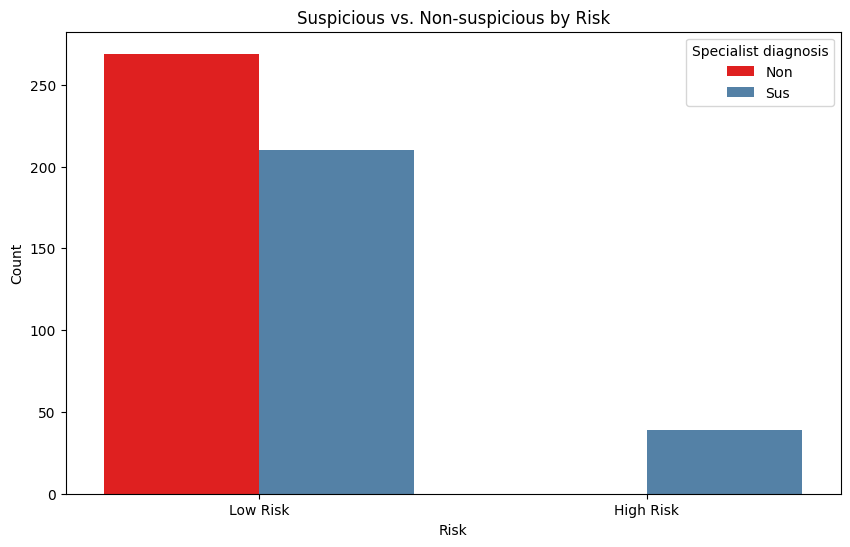

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
ax = sns.countplot(data=df, x='Risk', hue='Specialist diagnosis', palette={0: 'red', 1: 'steelblue'}) 

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, ['Non', 'Sus'], title='Specialist diagnosis')

ax.set_xticks([1,0])
ax.set_xticklabels(['High Risk', 'Low Risk'])
ax.set_xlabel('Risk')
ax.set_ylabel('Count')
plt.title('Suspicious vs. Non-suspicious by Risk')
plt.show()

In [8]:
import pandas as pd
cross_tab = pd.crosstab(df['Risk'], df['Specialist diagnosis'])
print(cross_tab) 

Specialist diagnosis    0    1
Risk                          
0                     269  210
1                       0   39


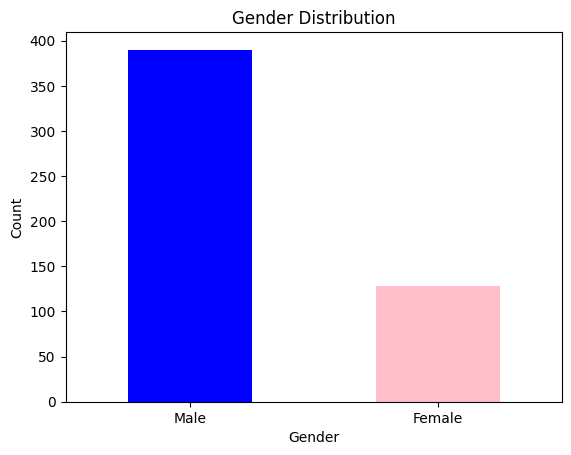

In [9]:
df['Gender'].value_counts().plot(kind='bar', color=['blue', 'pink'])
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.xticks([0, 1], ['Male','Female'], rotation=0)
plt.show()
# 388 Male 130 Female

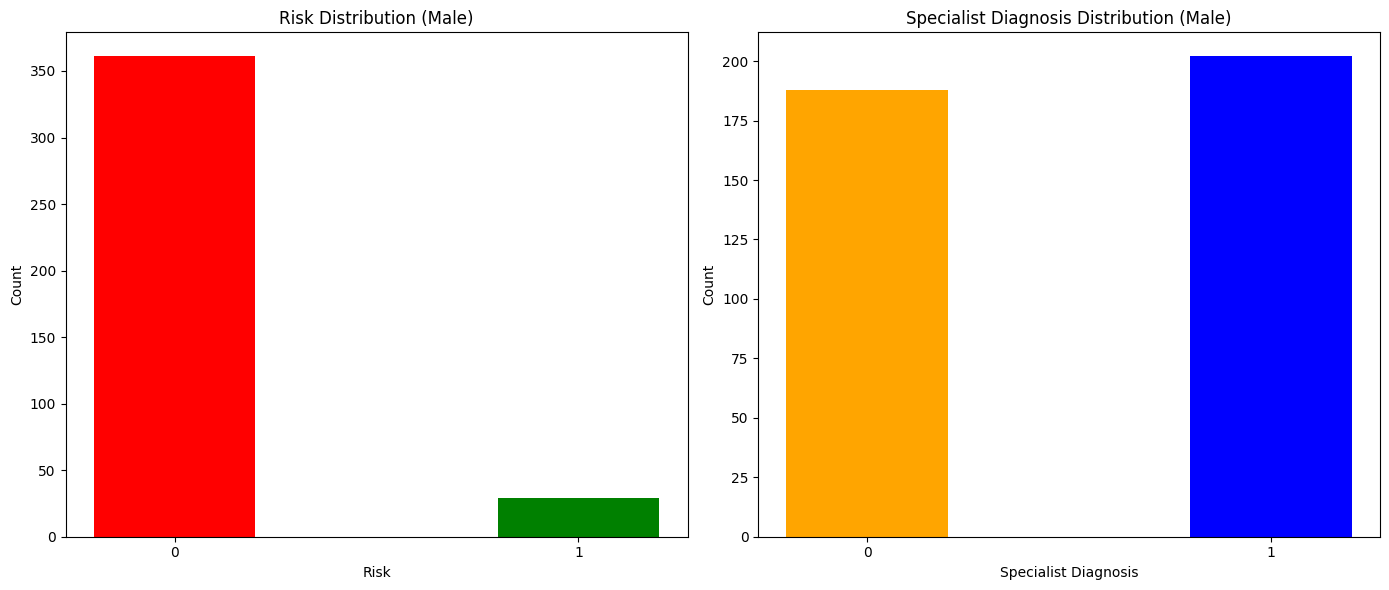

In [10]:
df['Gender'] = df['Gender'].astype(str)

male_df = df[df['Gender'] == '1']

risk_counts_male = male_df['Risk'].value_counts()
diagnosis_counts_male = male_df['Specialist diagnosis'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))


axes[0].bar(risk_counts_male.index, risk_counts_male.values, color=['red', 'green'], width=0.4)
axes[0].set_title('Risk Distribution (Male)')
axes[0].set_xlabel('Risk')
axes[0].set_ylabel('Count')
axes[0].set_xticks(risk_counts_male.index)

axes[1].bar(diagnosis_counts_male.index, diagnosis_counts_male.values, color=['blue', 'orange'], width=0.4)
axes[1].set_title('Specialist Diagnosis Distribution (Male)')
axes[1].set_xlabel('Specialist Diagnosis')
axes[1].set_ylabel('Count')
axes[1].set_xticks(diagnosis_counts_male.index)

plt.tight_layout()
plt.show()
# Total Male: 464
# Data Present: 388
#Male(Low Risk)  359
#Male(High Risk) 29
#Male(Non-suspicious) 188
#Male(Suspicious)  200

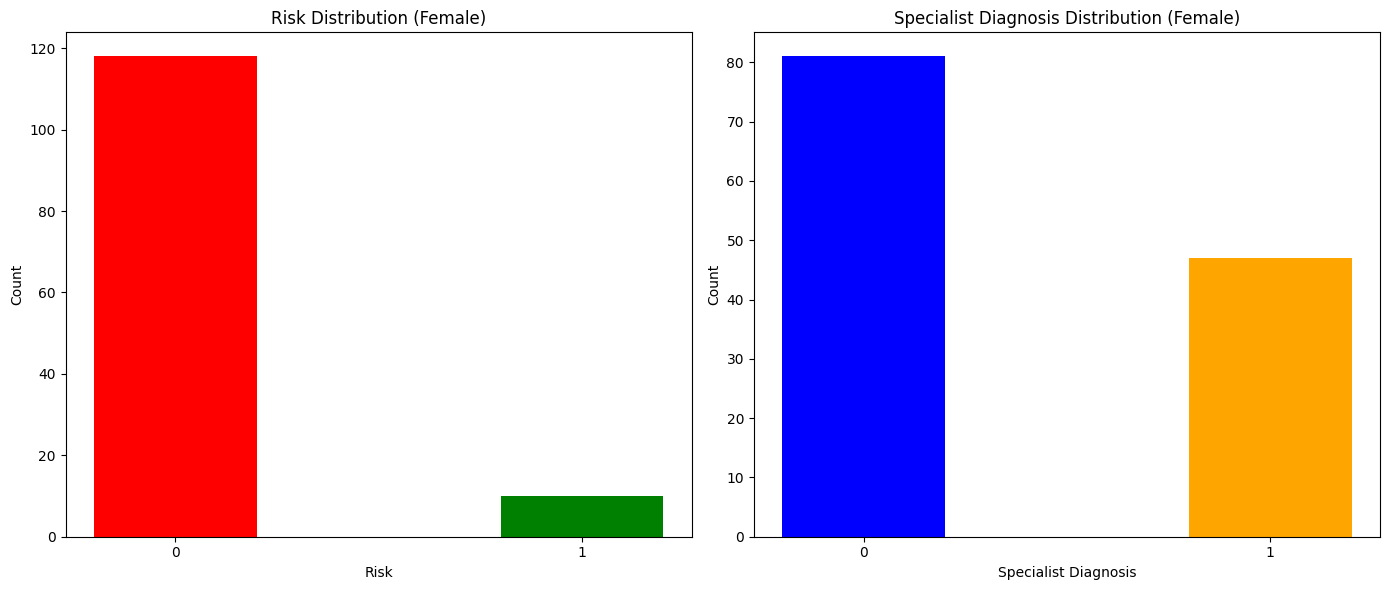

In [11]:
df['Gender'] = df['Gender'].astype(str)

male_df = df[df['Gender'] == '0']

risk_counts_female = male_df['Risk'].value_counts()
diagnosis_counts_female = male_df['Specialist diagnosis'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))


axes[0].bar(risk_counts_female.index, risk_counts_female.values, color=['red', 'green'], width=0.4)
axes[0].set_title('Risk Distribution (Female)')
axes[0].set_xlabel('Risk')
axes[0].set_ylabel('Count')
axes[0].set_xticks(risk_counts_female.index)

axes[1].bar(diagnosis_counts_female.index, diagnosis_counts_female.values, color=['blue', 'orange'], width=0.4)
axes[1].set_title('Specialist Diagnosis Distribution (Female)')
axes[1].set_xlabel('Specialist Diagnosis')
axes[1].set_ylabel('Count')
axes[1].set_xticks(diagnosis_counts_female.index)

plt.tight_layout()
plt.show()
# Total Female: 144 
# Data Present: 130
#Female(Low Risk)  120
#Female(High Risk) 10
#Female(Non-suspicious) 81
#Female(Suspicious)  49

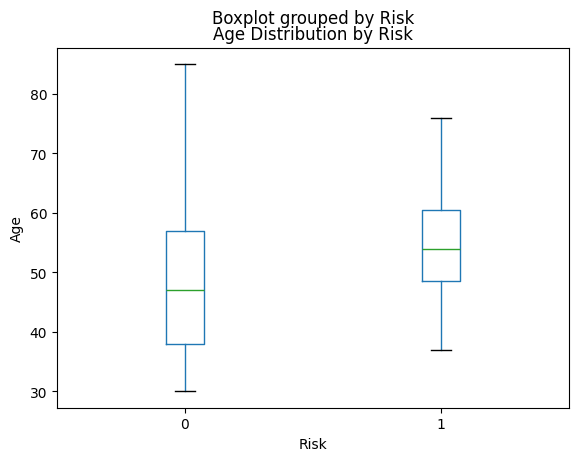

In [12]:
df.boxplot(column='Age', by='Risk', grid=False)
plt.title('Age Distribution by Risk')
plt.xlabel('Risk')
plt.ylabel('Age')
plt.show()

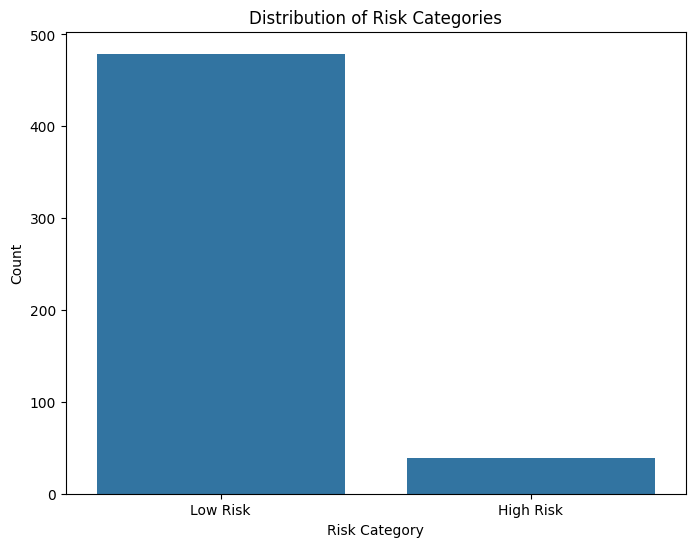

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='Risk')
plt.title('Distribution of Risk Categories')
# plt.legend(title='Risk Category',labels=['Low Risk','High Risk'])
plt.xlabel('Risk Category')
plt.xticks([0, 1],labels=['Low Risk','High Risk'])
plt.ylabel('Count')
plt.show()

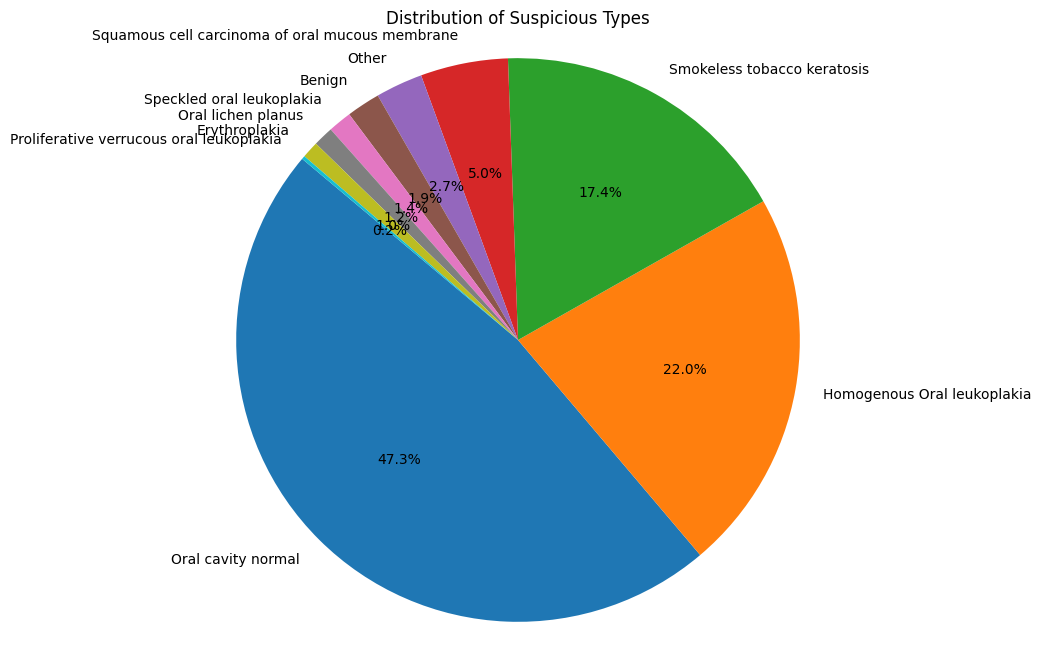

In [14]:
suspicious_counts = df['Provisional diagnosis'].value_counts()
plt.figure(figsize=(8, 8))
plt.pie(suspicious_counts, labels=suspicious_counts.index, autopct='%1.1f%%', startangle=140)
plt.title('Distribution of Suspicious Types')
plt.axis('equal') 
plt.show()

In [15]:
print(df.columns)

Index(['No.', 'Date of case registered', 'FLW username', 'Study setting',
       'Age', 'Gender', 'Cigarette/Bidi', 'Smokeless tobacco', 'Areca nut',
       'Alcohol', 'Able to open mouth', 'Lesion/patch',
       'Provisional diagnosis', 'Risk', 'Specialist diagnosis',
       'Specialist recommendation', 'Specialist notes', 'Image 1', 'Image 2',
       'Image 3', 'Image 4', 'Image 5', 'Image 6', 'Image 7', 'Image 8',
       'Image 9', 'Image 10', 'Image 11', 'Image 12', 'Image 13'],
      dtype='object')


In [16]:
print(df.shape)

(518, 30)
